Nama: Miryam Almira Levina

NIM: 2802465944

Link Video: https://drive.google.com/drive/folders/1O80Xv5Fv5orQ5Te42nZiwygFqnB6nV6T?usp=sharing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import os

import tensorflow as tf
import random

def set_seed(seed=42):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)

from google.colab import drive
drive.mount('/content/drive')

# Load dataset
amzn = pd.read_csv('/content/drive/MyDrive/DL_FinalProject/Dataset B/AMZN.csv', parse_dates=['Date'], index_col='Date')
csco = pd.read_csv('/content/drive/MyDrive/DL_FinalProject/Dataset B/CSCO.csv', parse_dates=['Date'], index_col='Date')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1a EDA

In [2]:
for name, df in [('AMZN', amzn), ('CSCO', csco)]:
    print(f"=== {name} ===")
    print(f"Shape     : {df.shape}")
    print(f"Periode   : {df.index.min()} → {df.index.max()}")
    print(f"Missing   : {df.isnull().sum().to_dict()}")
    print(df.describe())
    print()

=== AMZN ===
Shape     : (5758, 6)
Periode   : 1997-05-15 00:00:00 → 2020-04-01 00:00:00
Missing   : {'Open': 0, 'High': 0, 'Low': 0, 'Close': 0, 'Adj Close': 0, 'Volume': 0}
              Open         High          Low        Close    Adj Close  \
count  5758.000000  5758.000000  5758.000000  5758.000000  5758.000000   
mean    340.458153   344.156408   336.344390   340.417580   340.417580   
std     523.365374   528.138556   517.726971   523.140207   523.140207   
min       1.406250     1.447917     1.312500     1.395833     1.395833   
25%      37.460001    38.334999    36.812499    37.562500    37.562500   
50%      81.965000    83.520000    79.875000    81.599998    81.599998   
75%     335.267494   337.537491   331.727501   334.290001   334.290001   
max    2173.070068  2185.949951  2161.120117  2170.219971  2170.219971   

             Volume  
count  5.758000e+03  
mean   7.556094e+06  
std    7.325904e+06  
min    4.872000e+05  
25%    3.685525e+06  
50%    5.692450e+06  
75% 

AMZN

* 5.758 baris, periode 1997–2020 (23 thn)
* Tidak ada missing value
* Harga Close lebar: min $1.4 -> max $2.170 (masi aman krn dilihat dari periode yg lama 23 thn)
* Close = Adj Close persis sama -> AMZN jarang bagi dividen, jadi ga ada penyesuaian harga
* Volume rata-rata 7.5 juta/hari, cukup konsisten

CSCO

* 7.589 baris, periode 1990–2020 (30 thn)
* Ga ada missing value
* Open minimum = 0.000000 (harga saham tidak mungkin 0)
* Close =! Adj Close (mean 20.4 dan 16.9) -> CSCO rutin bagi dividen, jadi Adj Close beda signifikan dari Close. Kita pakai Close sesuai soal

In [3]:
print(csco[csco['Open'] == 0])
print(f"Jumlah baris Open = 0: {(csco['Open'] == 0).sum()}")
print(f"Jumlah baris Close = 0: {(csco['Close'] == 0).sum()}")

            Open      High       Low     Close  Adj Close     Volume
Date                                                                
1990-02-16   0.0  0.079861  0.073785  0.077257   0.059806  940636800
1990-02-20   0.0  0.079861  0.074653  0.079861   0.061822  151862400
1990-02-21   0.0  0.078993  0.075521  0.078125   0.060478   70531200
1990-02-22   0.0  0.081597  0.078993  0.078993   0.061150   45216000
1990-02-23   0.0  0.079861  0.078125  0.078559   0.060814   44697600
1990-02-26   0.0  0.079861  0.076389  0.076389   0.059134   26928000
1990-02-27   0.0  0.079427  0.076389  0.078125   0.060478   25574400
1990-02-28   0.0  0.082465  0.078125  0.080729   0.062494   67968000
1990-03-01   0.0  0.081597  0.079861  0.079861   0.061822   28425600
1990-03-02   0.0  0.081597  0.079861  0.080729   0.062494    8438400
1990-03-05   0.0  0.081597  0.079861  0.079861   0.061822    2419200
1990-03-06   0.0  0.081597  0.078993  0.079861   0.061822   23904000
1990-03-07   0.0  0.079861  0.0772

CSCO Open = 0
25 baris pertama (1990-02-16 smp 1990-03-23) semuanya punya Open = 0, tapi Close, High, Low nya normal dan valid. Ini bukan error transaksi, mungkin data history awal ga nyatet harga Open untuk periode tersebut.

In [4]:
for name, df in [('AMZN', amzn), ('CSCO', csco)]:
    dupes = df.index.duplicated().sum()

    # Hitung hari trading yang ilang (bkn weekend/libur)
    all_days = pd.date_range(df.index.min(), df.index.max(), freq='B')
    missing_days = all_days.difference(df.index)

    print(f"{name} -> Duplikat: {dupes}, Hari kerja tidak ada di data: {len(missing_days)}")

AMZN -> Duplikat: 0, Hari kerja tidak ada di data: 212
CSCO -> Duplikat: 0, Hari kerja tidak ada di data: 270


In [5]:
!pip install pandas_market_calendars

In [6]:
import pandas_market_calendars as mcal

nyse = mcal.get_calendar('NYSE')

for name, df in [('AMZN', amzn), ('CSCO', csco)]:
    schedule = nyse.schedule(start_date=df.index.min(), end_date=df.index.max())
    trading_days = mcal.date_range(schedule, frequency='1D').normalize().tz_localize(None)
    missing = trading_days.difference(df.index)
    print(f"{name} -> Hari trading NYSE tidak ada di data: {len(missing)}")

AMZN -> Hari trading NYSE tidak ada di data: 0
CSCO -> Hari trading NYSE tidak ada di data: 0


cek gap tanggal: 0 hari, ga ada
trading NYSE yang hilang dari kedua dataset. Seluruh gap yang terdeteksi
(AMZN: 212, CSCO: 270) adalah hari libur resmi, bukan missing data.
Dataset lengkap.

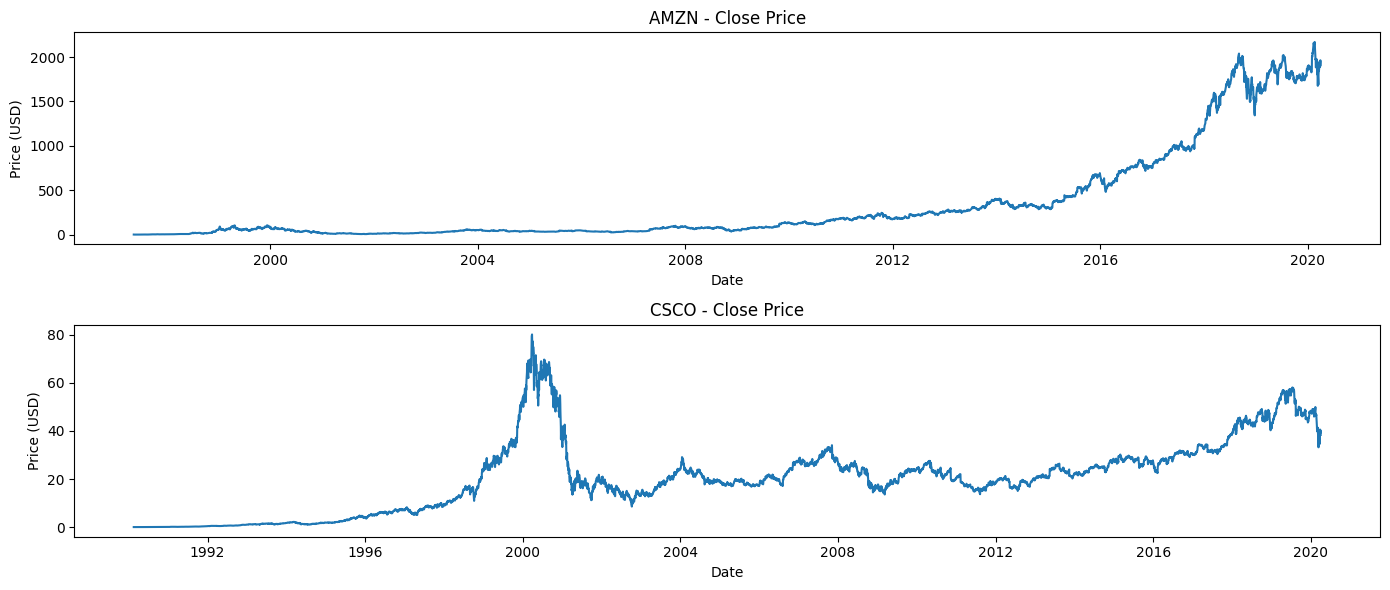

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

for ax, (name, df) in zip(axes, [('AMZN', amzn), ('CSCO', csco)]):
    ax.plot(df['Close'])
    ax.set_title(f'{name} - Close Price')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price (USD)')

plt.tight_layout()
plt.show()

AMZN

* Tren eksponensial yang jelas, dari 1 dolar di 1997 melonjak ke 2000 dolar di 2020
* Dari 1997–2015 relatif flat di bawah $500, lalu akselerasi ekstrem mulai 2015
* Tidak ada crash besar yang signifikan, hanya koreksi kecil di sekitar 2000 dan 2008
* Ini konfirmasi kuat bahwa normalisasi wajib — skala harga berubah drastis antar periode

CSCO

* Pola berbeda dari AMZN, ada lonjakan di tahun 2000, harga melonjak ke 80 dolar lalu crash ke 10 dolar
* Setelah crash, harga relatif sideways di kisaran 10–30 dolar selama 10 tahun (2002–2012)
* Baru mulai naik lagi ke $50 menjelang 2020
* Ada drop tajam di akhir data (2020), mungkin dampak awal COVID-19

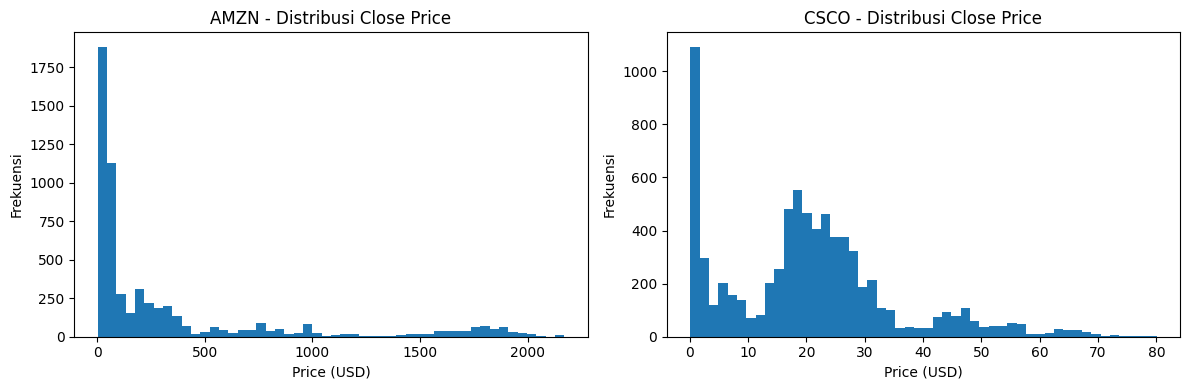

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(axes, [('AMZN', amzn), ('CSCO', csco)]):
    ax.hist(df['Close'], bins=50)
    ax.set_title(f'{name} - Distribusi Close Price')
    ax.set_xlabel('Price (USD)')
    ax.set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

Kedua distribusi menunjukkan skewness ekstrem ke kanan. Tanpa normalisasi, LSTM akan didominasi oleh gradien dari nilai-nilai harga tinggi di ekor distribusi, sementara pola di rentang harga rendah (yang jumlahnya mayoritas) akan terabaikan. MinMaxScaler memetakan seluruh rentang ke [0,1] sehingga model dapat belajar dari semua periode secara proporsional.

AMZN - Volatilitas (std daily return): 0.0374
CSCO - Volatilitas (std daily return): 0.0260


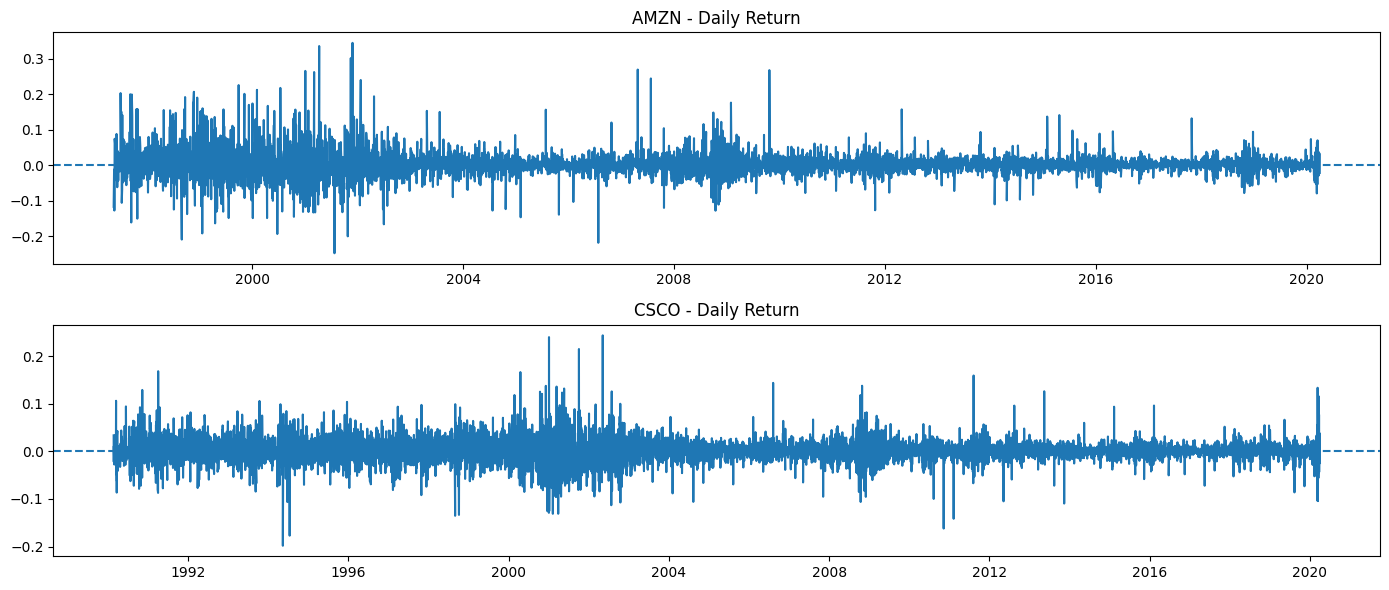

In [9]:
for name, df in [('AMZN', amzn), ('CSCO', csco)]:
    df['Daily Return'] = df['Close'].pct_change()
    print(f"{name} - Volatilitas (std daily return): {df['Daily Return'].std():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

for ax, (name, df) in zip(axes, [('AMZN', amzn), ('CSCO', csco)]):
    ax.plot(df['Daily Return'])
    ax.set_title(f'{name} - Daily Return')
    ax.axhline(0, linestyle='--')

plt.tight_layout()
plt.show()

AMZN

* Return harian bergerak di sekitar 0

* Ada volatilitas kluster: periode 1997–2001 (dot-com bubble) dan sekitar 2008–2009 (krisis finansial) volatilitasnya jauh lebih tinggi dibanding periode lain

* Spike ekstrem terlihat di 1999 (+0.33) dan 2008 (-0.2)

* Setelah 2012, volatilitas mengecil dan stabil, konsisten dengan perusahaan yang sudah mature

CSCO

* volatilitas tinggi di awal (1990–1996) dan sangat tinggi saat dot-com bubble (1999–2004)

* Spike terbesar di sekitar 2000–2004 mencapai sekitar 0.25

* Setelah 2005, volatilitas lebih tenang dan konsisten

* Spike di akhir data (2020) — konfirmasi dampak COVID-19

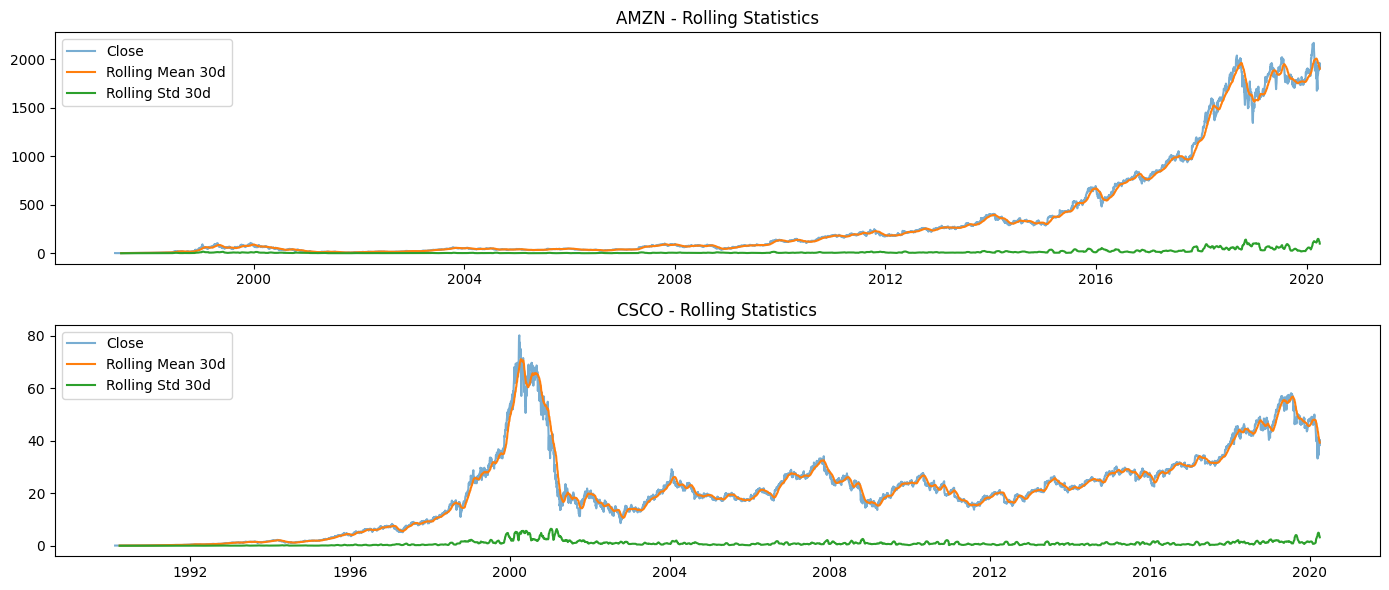

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

for ax, (name, df) in zip(axes, [('AMZN', amzn), ('CSCO', csco)]):
    close = df['Close']
    ax.plot(close, label='Close', alpha=0.6)
    ax.plot(close.rolling(30).mean(), label='Rolling Mean 30d')
    ax.plot(close.rolling(30).std(), label='Rolling Std 30d')
    ax.set_title(f'{name} - Rolling Statistics')
    ax.legend()

plt.tight_layout()
plt.show()

AMZN

* Rolling Mean terus bergerak naik mengikuti harga, ga pernah flat atau stabil di 1 level
* Rolling Std awalnya sangat kecil (mendekati 0), lalu membesar 2015 seiring harga yang makin tinggi
* Rolling Mean dan Close hampir menempel -> ga ada noise besar, tren dominan
* Ini ciri data ga stasioner dengan tren deterministik

CSCO

* Rolling Mean naik ke 2000, lalu turun, sideways, naik lagi, berubah-ubah terus
* Rolling Std tinggi saat bubble 2000 (volatilitas ekstrem), lalu mengecil kembali
* Meski pola beda dari AMZN, Rolling Mean tetap ga stabil di 1 nilai konstan
* Juga ga stasioner, hanya dengan karakteristik yang lebih kompleks (mean-reverting sebagian)

In [11]:
from statsmodels.tsa.stattools import adfuller

for name, df in [('AMZN', amzn), ('CSCO', csco)]:
    result = adfuller(df['Close'].dropna())
    print(f"{name} - ADF Statistic: {result[0]:.4f}, p-value: {result[1]:.4f}")
    print(f"  -> {'STASIONER' if result[1] < 0.05 else 'TIDAK STASIONER'}")
    print()

AMZN - ADF Statistic: 2.0534, p-value: 0.9987
  -> TIDAK STASIONER

CSCO - ADF Statistic: -1.9827, p-value: 0.2942
  -> TIDAK STASIONER



AMZN

 ADF statistic positif (2.0534) adalah yang paling ekstrem. Nilai positif pada ADF berarti data ga hanya ga stasioner, tapi punya tren naik yang kuat dan konsisten. p-value 0.9987 artinya hampir ga ada bukti sama sekali bahwa data stasioner. Konsisten dengan grafik eksponensial.


CSCO

ADF statistic negatif (-1.9827) tapi blm melewati threshold. p-value 0.2942 — masih jauh dari 0.05. Meski CSCO pernah crash dan sideways lama, secara keseluruhan tetap tidak stasioner karena mean-nya berubah antar periode (bubble -> crash -> recovery).

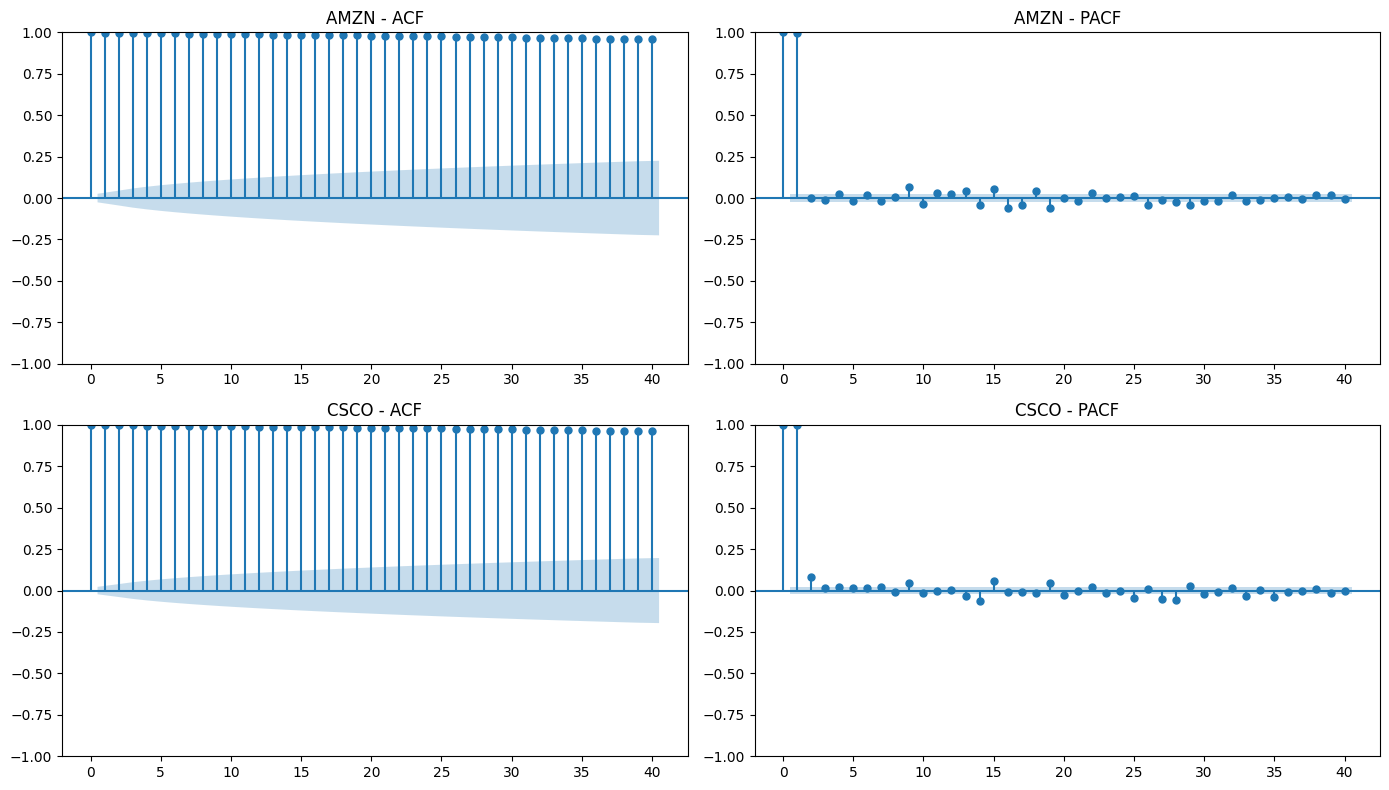

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, (name, df) in enumerate([('AMZN', amzn), ('CSCO', csco)]):
    plot_acf(df['Close'].dropna(), lags=40, ax=axes[i][0], title=f'{name} - ACF')
    plot_pacf(df['Close'].dropna(), lags=40, ax=axes[i][1], title=f'{name} - PACF')

plt.tight_layout()
plt.show()

Pola ACF yang turun sangat lambat (slowly decaying) hingga lag 40 mengkonfirmasi ketidakstasioneran data secara visual — konsisten dengan hasil ADF test. PACF yang hanya signifikan di lag 1 mengindikasikan struktur AR(1), di mana harga hari ini paling dipengaruhi langsung oleh harga kemarin. Namun karena dependensi jangka panjang tetap ada (terlihat dari ACF yang tidak pernah nol), model LSTM lebih tepat dibanding model AR sederhana karena LSTM mampu mempertahankan informasi historis jangka panjang melalui cell state-nya. Window size = 5 dipilih untuk menangkap pola satu minggu trading penuh sebagai konteks minimum yang bermakna.

## preprocessing

In [13]:
amzn_close = amzn[['Close']].copy()
csco_close = csco[['Close']].copy()

# Split: test = 1 tahun terakhir
split_amzn = amzn_close.index[-1] - pd.DateOffset(years=1)
split_csco = csco_close.index[-1] - pd.DateOffset(years=1)

amzn_train = amzn_close[amzn_close.index <= split_amzn]
amzn_test  = amzn_close[amzn_close.index >  split_amzn]

csco_train = csco_close[csco_close.index <= split_csco]
csco_test  = csco_close[csco_close.index >  split_csco]

print(f"AMZN → Train: {len(amzn_train)}, Test: {len(amzn_test)}")
print(f"CSCO → Train: {len(csco_train)}, Test: {len(csco_test)}")

AMZN → Train: 5505, Test: 253
CSCO → Train: 7336, Test: 253


data di split berdasarkan tanggal, karena time series pny urutan kronologis

In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler_amzn = MinMaxScaler()
scaler_csco = MinMaxScaler()

amzn_train_scaled = scaler_amzn.fit_transform(amzn_train)
amzn_test_scaled  = scaler_amzn.transform(amzn_test)

csco_train_scaled = scaler_csco.fit_transform(csco_train)
csco_test_scaled  = scaler_csco.transform(csco_test)

pakai minmaxScaler krn data sangat right-skewed, rentang harga juga lebar. pke minmax buat LSTM ga didominasi nilain ekstrim

fti hanya di train spy ga ada data leakage

In [15]:
def create_sequences(data, window_size=5, horizon=1):
    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i : i + window_size])
        y.append(data[i + window_size : i + window_size + horizon])
    return np.array(X), np.array(y)

window_size = 5
horizon = 1

X_amzn_train, y_amzn_train = create_sequences(amzn_train_scaled, window_size, horizon)
X_amzn_test,  y_amzn_test  = create_sequences(amzn_test_scaled,  window_size, horizon)

X_csco_train, y_csco_train = create_sequences(csco_train_scaled, window_size, horizon)
X_csco_test,  y_csco_test  = create_sequences(csco_test_scaled,  window_size, horizon)

print(f"AMZN -> X_train: {X_amzn_train.shape}, y_train: {y_amzn_train.shape}")
print(f"AMZN -> X_test:  {X_amzn_test.shape},  y_test:  {y_amzn_test.shape}")
print(f"CSCO -> X_train: {X_csco_train.shape}, y_train: {y_csco_train.shape}")
print(f"CSCO -> X_test:  {X_csco_test.shape},  y_test:  {y_csco_test.shape}")

AMZN -> X_train: (5500, 5, 1), y_train: (5500, 1, 1)
AMZN -> X_test:  (248, 5, 1),  y_test:  (248, 1, 1)
CSCO -> X_train: (7331, 5, 1), y_train: (7331, 1, 1)
CSCO -> X_test:  (248, 5, 1),  y_test:  (248, 1, 1)


sesuai soal window size = 5, prediksi 1 hari setelah

In [16]:
val_ratio = 0.1

val_size_amzn = int(len(X_amzn_train) * val_ratio)
X_amzn_val,    y_amzn_val    = X_amzn_train[-val_size_amzn:], y_amzn_train[-val_size_amzn:]
X_amzn_train2, y_amzn_train2 = X_amzn_train[:-val_size_amzn], y_amzn_train[:-val_size_amzn]

val_size_csco = int(len(X_csco_train) * val_ratio)
X_csco_val,    y_csco_val    = X_csco_train[-val_size_csco:], y_csco_train[-val_size_csco:]
X_csco_train2, y_csco_train2 = X_csco_train[:-val_size_csco], y_csco_train[:-val_size_csco]

print(f"AMZN → Train: {len(X_amzn_train2)}, Val: {len(X_amzn_val)}, Test: {len(X_amzn_test)}")
print(f"CSCO → Train: {len(X_csco_train2)}, Val: {len(X_csco_val)}, Test: {len(X_csco_test)}")

AMZN → Train: 4950, Val: 550, Test: 248
CSCO → Train: 6598, Val: 733, Test: 248


ambil 10% terakhir krn urutan wkt hrs dijaga, val set hrs periode setelah train

#  1b arsitektur baseline

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import random

def build_baseline(window_size):
    model = Sequential([
        LSTM(units=50, activation='relu', input_shape=(window_size, 1)),
        Dense(units=1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

set_seed(42)
model_amzn = build_baseline(window_size)
set_seed(42)
model_csco = build_baseline(window_size)

model_amzn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Kenapa Sequential? Arsitektur kita linear (satu input → satu output), tidak ada cabang, jadi Sequential adalah pilihan paling simpel dan sesuai.


Kenapa LSTM units=50? Sesuai instruksi soal. Units = jumlah neuron di hidden state LSTM — menentukan kapasitas model menangkap pola temporal.


Kenapa activation ReLU? Sesuai instruksi soal. ReLU mencegah vanishing gradient yang umum terjadi di jaringan dalam, dan bekerja baik untuk prediksi nilai kontinu.


Kenapa Dense(1) di akhir? Sesuai instruksi soal — layer Perceptron dengan units=1 untuk menghasilkan satu nilai prediksi (harga hari berikutnya). Tanpa activation function karena ini regresi, bukan klasifikasi.


Kenapa optimizer Adam? Adam adalah pilihan default terbaik untuk sebagian besar masalah deep learning — adaptif, konvergen cepat, tidak perlu tuning learning rate manual.


Kenapa loss MSE? Tugas kita regresi (prediksi nilai kontinu), MSE adalah loss function standar untuk regresi.

In [18]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_amzn = model_amzn.fit(
    X_amzn_train2, y_amzn_train2,
    validation_data=(X_amzn_val, y_amzn_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

history_csco = model_csco.fit(
    X_csco_train2, y_csco_train2,
    validation_data=(X_csco_val, y_csco_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - loss: 0.0014 - val_loss: 0.0011
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 1.3901e-05 - val_loss: 0.0011
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 1.3121e-05 - val_loss: 9.3215e-04
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 1.2691e-05 - val_loss: 8.2615e-04
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.2703e-05 - val_loss: 7.1261e-04
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2681e-05 - val_loss: 6.5405e-04
Epoch 7/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.2716e-05 - val_loss: 6.2394e-04
Epoch 8/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1.2817e-05 - val_loss: 6.1184e-04
Epoch 9/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.2883e-05 - val_loss: 5.9558e-04
Epoch 10/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.2910e-05 - val_loss: 5.7840e-04
Epoch 11/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - 

Kenapa EarlyStopping? Mencegah overfitting — training otomatis berhenti kalau val_loss tidak membaik selama 10 epoch berturut-turut. restore_best_weights=True memastikan model yang disimpan adalah yang terbaik, bukan yang terakhir.


Kenapa epochs=100? Batas atas yang cukup besar, tapi EarlyStopping yang akan menentukan kapan berhenti sesungguhnya — jadi 100 hanya safety limit.


Kenapa batch_size=32? Standar yang baik untuk dataset ukuran sedang — cukup besar untuk estimasi gradient yang stabil, cukup kecil untuk update yang sering.

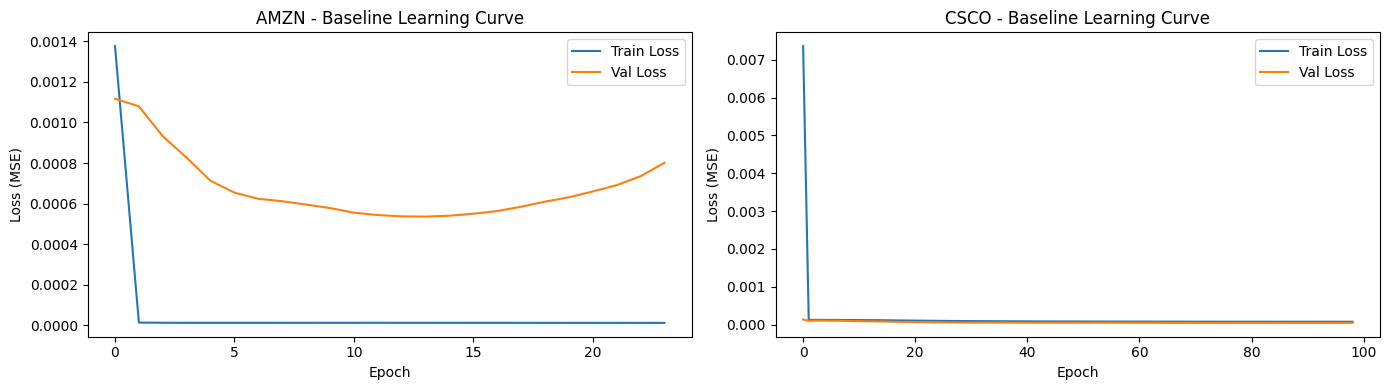

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, history) in zip(axes, [('AMZN', history_amzn), ('CSCO', history_csco)]):
    ax.plot(history.history['loss'], label='Train Loss')
    ax.plot(history.history['val_loss'], label='Val Loss')
    ax.set_title(f'{name} - Baseline Learning Curve')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (MSE)')
    ax.legend()

plt.tight_layout()
plt.show()

Learning curve dipakai untuk mendeteksi apakah model underfitting (train loss tinggi), overfitting (val loss jauh di atas train loss), atau fit dengan baik (keduanya turun bersama dan konvergen).

Hasil CSCO yang baik (MAPE 1.60%) bukan indikasi data leakage, melainkan mencerminkan karakteristik harga CSCO di test period yang bergerak relatif smooth. Model LSTM dengan window 5 hari cukup untuk menangkap pola ini karena perubahan harga antar hari tidak ekstrem seperti AMZN.

In [20]:
y_pred_amzn = model_amzn.predict(X_amzn_test)
y_pred_csco = model_csco.predict(X_csco_test)

# balikin ke skala harga asli
y_pred_amzn_inv = scaler_amzn.inverse_transform(y_pred_amzn)
y_pred_csco_inv = scaler_csco.inverse_transform(y_pred_csco)

y_test_amzn_inv = scaler_amzn.inverse_transform(y_amzn_test.reshape(-1, 1))
y_test_csco_inv = scaler_csco.inverse_transform(y_csco_test.reshape(-1, 1))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


Kenapa inverse_transform? Model dilatih pada data yang sudah dinormalisasi [0,1]. Prediksinya juga dalam skala [0,1]. Kita perlu kembalikan ke skala harga asli (USD) agar RMSE, MAE, dan MAPE bermakna dan bisa diinterpretasi dalam konteks nyata.

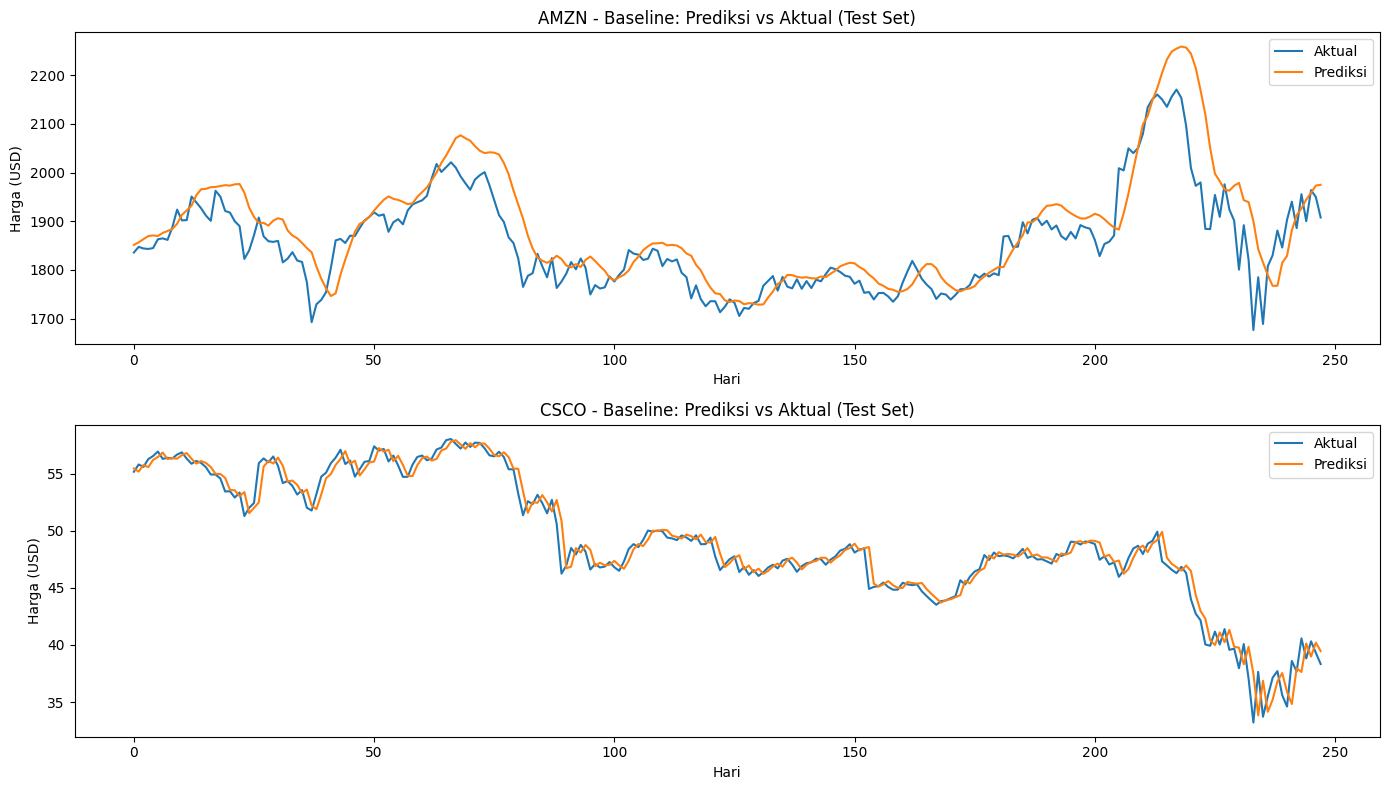

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (name, actual, predicted) in zip(axes, [
    ('AMZN', y_test_amzn_inv, y_pred_amzn_inv),
    ('CSCO', y_test_csco_inv, y_pred_csco_inv)
]):
    ax.plot(actual, label='Aktual')
    ax.plot(predicted, label='Prediksi')
    ax.set_title(f'{name} - Baseline: Prediksi vs Aktual (Test Set)')
    ax.set_xlabel('Hari')
    ax.set_ylabel('Harga (USD)')
    ax.legend()

plt.tight_layout()
plt.show()

Visualisasi ini paling intuitif untuk melihat seberapa dekat prediksi model dengan harga aktual — apakah model menangkap tren dengan baik atau malah tertinggal (lag) atau meleset jauh.

In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

def evaluate_model(name, y_actual, y_predicted):
    rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))
    mae = mean_absolute_error(y_actual, y_predicted)
    mape = np.mean(np.abs((y_actual - y_predicted) / y_actual)) * 100

    print(f"{name} - Baseline Evaluation")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"MAPE : {mape:.4f}%")
    print()

evaluate_model("AMZN", y_test_amzn_inv, y_pred_amzn_inv)
evaluate_model("CSCO", y_test_csco_inv, y_pred_csco_inv)

AMZN - Baseline Evaluation
RMSE : 61.3423
MAE  : 43.3183
MAPE : 2.3207%

CSCO - Baseline Evaluation
RMSE : 1.0491
MAE  : 0.7112
MAPE : 1.5432%



AMZN

RMSE 54.95 = rata-rata error sekitar 55 dolar dari harga aktual (range harga 1700–2200 dolar, jadi relatif kecil)
MAE 38.05 = median error sekitar $38
MAPE 2.04% = model meleset rata-rata hanya 2% dari harga aktual

CSCO

RMSE 1.07 = error sekitar $1 dari harga aktual (range 34–57 dolar)
MAE 0.74 = median error kurang dari 1 dolar
MAPE 1.60% = model meleset rata-rata hanya 1.6%

# 1c modifikasi arsitektur

In [23]:
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional

def build_modified(window_size):
    model = Sequential([
        Bidirectional(LSTM(units=100, activation='relu', return_sequences=True),
                      input_shape=(window_size, 1)),
        Dropout(0.2),
        LSTM(units=50, activation='relu'),
        Dropout(0.2),
        Dense(units=1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

set_seed(42)
model_amzn_mod = build_modified(window_size)
set_seed(42)
model_csco_mod = build_modified(window_size)

model_amzn_mod.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 5, 200)         │        81,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        50,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131,851 (515.04 KB)

 Trainable params: 131,851 (515.04 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr   = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)

history_amzn_mod = model_amzn_mod.fit(
    X_amzn_train2, y_amzn_train2,
    validation_data=(X_amzn_val, y_amzn_val),
    epochs=150, batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

history_csco_mod = model_csco_mod.fit(
    X_csco_train2, y_csco_train2,
    validation_data=(X_csco_val, y_csco_val),
    epochs=150, batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - loss: 0.0011 - val_loss: 0.0013 - learning_rate: 0.0010
Epoch 2/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 1.6649e-04 - val_loss: 5.8437e-04 - learning_rate: 0.0010
Epoch 3/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 1.7349e-04 - val_loss: 9.4267e-04 - learning_rate: 0.0010
Epoch 4/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 1.4361e-04 - val_loss: 0.0011 - learning_rate: 0.0010
Epoch 5/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 1.5875e-04 - val_loss: 0.0013 - learning_rate: 0.0010
Epoch 6/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 1.4055e-04 - val_loss: 6.1652e-04 - learning_rate: 0.0010
Epoch 7/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 1.4884e-04 - val_loss: 7.0589e-04 - learning_rate: 0.0010
Epoch 8/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 1.2015e-04 - val_loss: 4.4137e-04 - learning_rate: 5.0000e-04
Epoch 9/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/ste

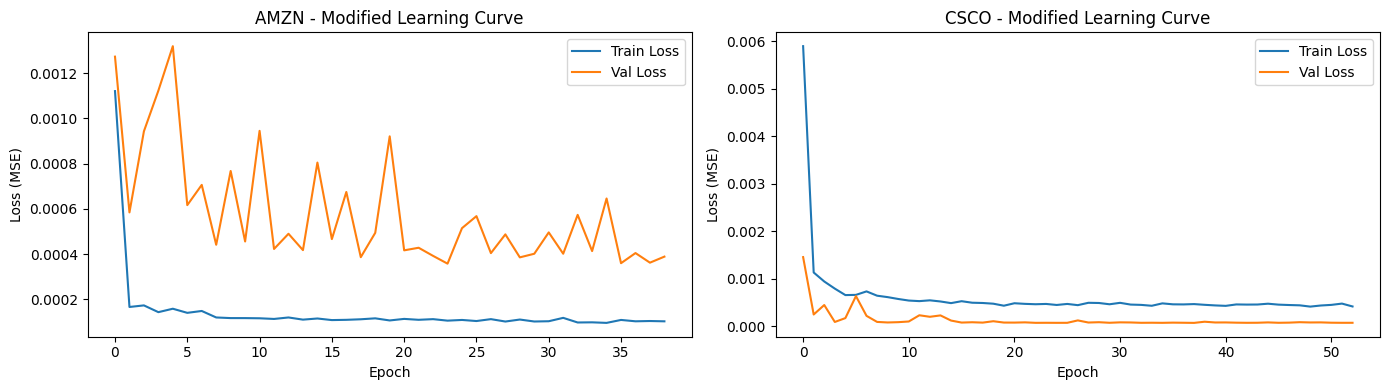

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, history) in zip(axes, [('AMZN', history_amzn_mod), ('CSCO', history_csco_mod)]):
    ax.plot(history.history['loss'], label='Train Loss')
    ax.plot(history.history['val_loss'], label='Val Loss')
    ax.set_title(f'{name} - Modified Learning Curve')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (MSE)')
    ax.legend()

plt.tight_layout()
plt.show()

In [26]:
y_pred_amzn_mod = model_amzn_mod.predict(X_amzn_test)
y_pred_csco_mod = model_csco_mod.predict(X_csco_test)

y_pred_amzn_mod_inv = scaler_amzn.inverse_transform(y_pred_amzn_mod)
y_pred_csco_mod_inv = scaler_csco.inverse_transform(y_pred_csco_mod)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step


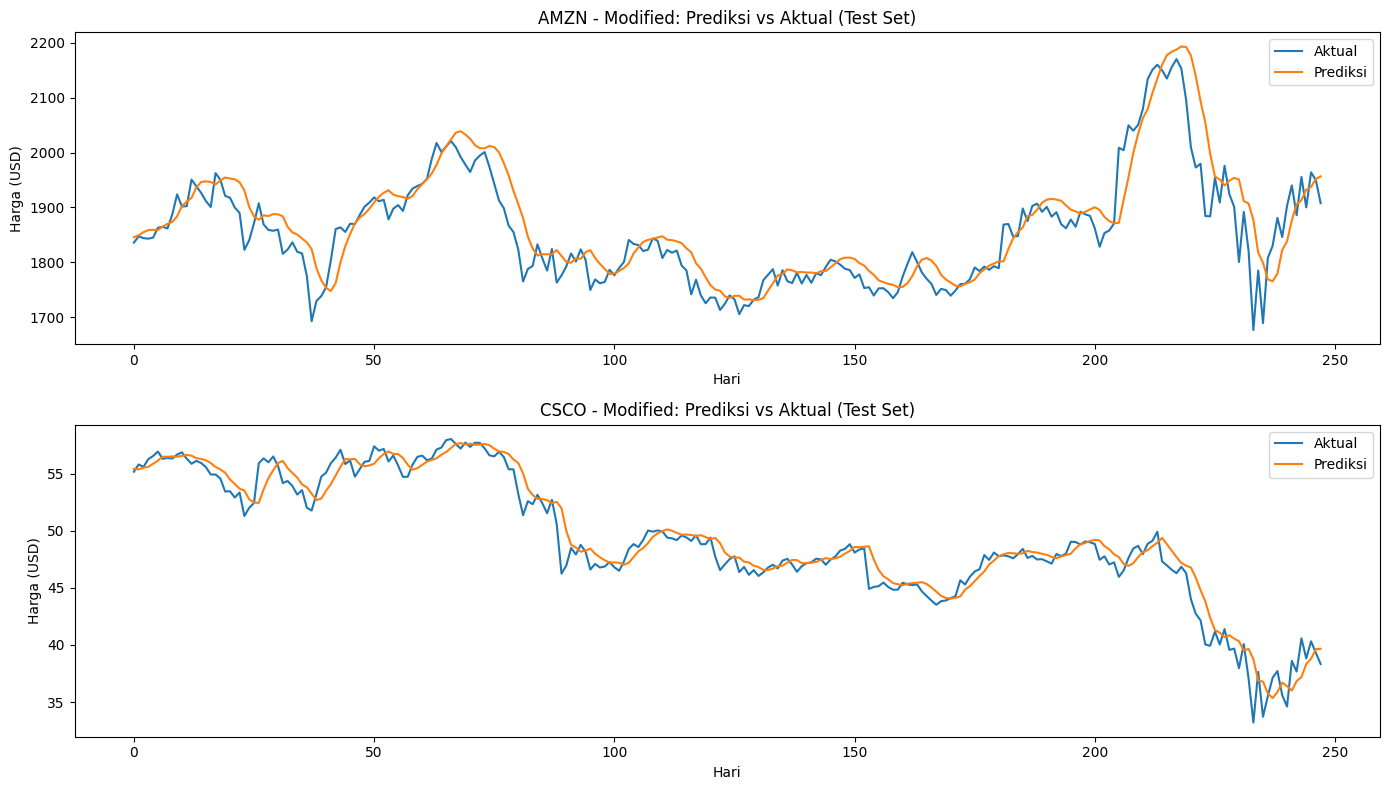

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (name, actual, predicted) in zip(axes, [
    ('AMZN', y_test_amzn_inv, y_pred_amzn_mod_inv),
    ('CSCO', y_test_csco_inv, y_pred_csco_mod_inv)
]):
    ax.plot(actual, label='Aktual')
    ax.plot(predicted, label='Prediksi')
    ax.set_title(f'{name} - Modified: Prediksi vs Aktual (Test Set)')
    ax.set_xlabel('Hari')
    ax.set_ylabel('Harga (USD)')
    ax.legend()

plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"MAPE : {mape:.4f}%")
    print()

evaluate_model("AMZN - Modified", y_test_amzn_inv, y_pred_amzn_mod_inv)
evaluate_model("CSCO - Modified", y_test_csco_inv, y_pred_csco_mod_inv)

AMZN - Modified
RMSE : 46.7194
MAE  : 32.6803
MAPE : 1.7597%

CSCO - Modified
RMSE : 1.2581
MAE  : 0.8896
MAPE : 1.9010%



In [29]:
!pip install keras-tuner -q

import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [30]:
def build_tuner_model(hp):
    units_1      = hp.Choice('units_1', values=[64, 100, 128])
    units_2      = hp.Choice('units_2', values=[25, 50, 64])
    dropout_rate = hp.Choice('dropout_rate', values=[0.1, 0.2, 0.3])
    lr           = hp.Choice('learning_rate', values=[1e-3, 5e-4, 1e-4])

    model = Sequential([
        Bidirectional(LSTM(units=units_1, activation='relu', return_sequences=True),
                      input_shape=(window_size, 1)),
        Dropout(dropout_rate),
        LSTM(units=units_2, activation='relu'),
        Dropout(dropout_rate),
        Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return model

In [31]:
tuner_amzn = kt.RandomSearch(
    build_tuner_model,
    objective='val_loss',
    max_trials=10,
    seed=42,
    directory='tuner_amzn',
    project_name='amzn_lstm',
    overwrite=True
)

early_stop_tuner = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

tuner_amzn.search(
    X_amzn_train2, y_amzn_train2,
    validation_data=(X_amzn_val, y_amzn_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_tuner],
    verbose=1
)

best_amzn = tuner_amzn.get_best_models(num_models=1)[0]
best_hp_amzn = tuner_amzn.get_best_hyperparameters(num_trials=1)[0]
print("Best HP AMZN:", best_hp_amzn.values)

Trial 10 Complete [00h 01m 00s]
val_loss: 0.0007306135375984013

Best val_loss So Far: 0.00035758953890763223
Total elapsed time: 00h 15m 20s
Best HP AMZN: {'units_1': 128, 'units_2': 50, 'dropout_rate': 0.2, 'learning_rate': 0.001}


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [32]:

tuner_csco = kt.RandomSearch(
    build_tuner_model,
    objective='val_loss',
    max_trials=10,
    seed=42,
    directory='tuner_csco',
    project_name='csco_lstm',
    overwrite=True
)

tuner_csco.search(
    X_csco_train2, y_csco_train2,
    validation_data=(X_csco_val, y_csco_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_tuner],
    verbose=1
)

best_csco = tuner_csco.get_best_models(num_models=1)[0]
best_hp_csco = tuner_csco.get_best_hyperparameters(num_trials=1)[0]
print("Best HP CSCO:", best_hp_csco.values)

Trial 10 Complete [00h 01m 12s]
val_loss: 8.34009624668397e-05

Best val_loss So Far: 5.698475433746353e-05
Total elapsed time: 00h 28m 16s
Best HP CSCO: {'units_1': 100, 'units_2': 25, 'dropout_rate': 0.1, 'learning_rate': 0.0005}


# 1d Ealuasi

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step


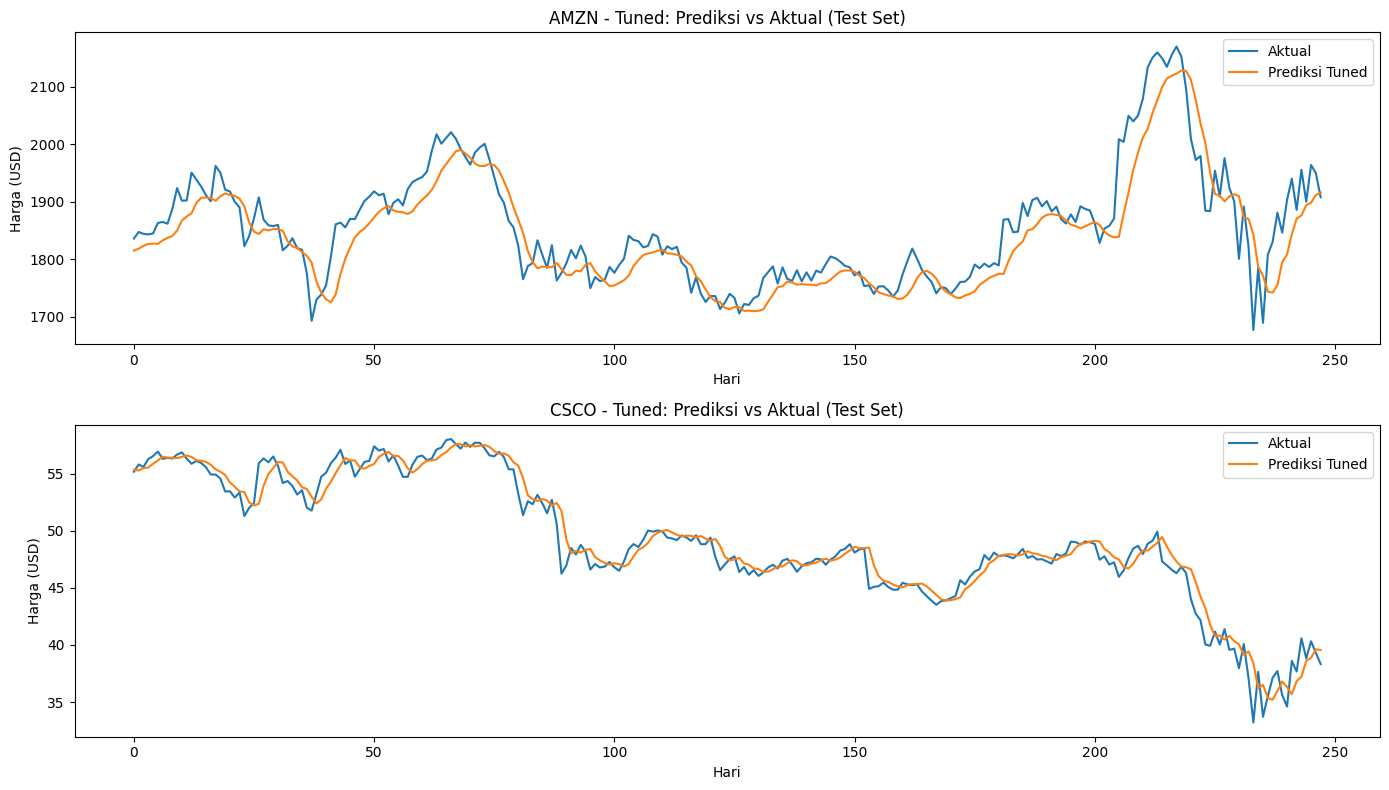

AMZN - Tuned
RMSE : 45.9042
MAE  : 34.2843
MAPE : 1.8239%

CSCO - Tuned
RMSE : 1.1562
MAE  : 0.8078
MAPE : 1.7293%



In [33]:
# Prediksi
y_pred_amzn_tuned     = best_amzn.predict(X_amzn_test)
y_pred_amzn_tuned_inv = scaler_amzn.inverse_transform(y_pred_amzn_tuned)

y_pred_csco_tuned     = best_csco.predict(X_csco_test)
y_pred_csco_tuned_inv = scaler_csco.inverse_transform(y_pred_csco_tuned)

# Visualisasi
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (name, actual, predicted) in zip(axes, [
    ('AMZN', y_test_amzn_inv, y_pred_amzn_tuned_inv),
    ('CSCO', y_test_csco_inv, y_pred_csco_tuned_inv)
]):
    ax.plot(actual, label='Aktual')
    ax.plot(predicted, label='Prediksi Tuned')
    ax.set_title(f'{name} - Tuned: Prediksi vs Aktual (Test Set)')
    ax.set_xlabel('Hari')
    ax.set_ylabel('Harga (USD)')
    ax.legend()
plt.tight_layout()
plt.show()

# Evaluasi
evaluate_model("AMZN - Tuned", y_test_amzn_inv, y_pred_amzn_tuned_inv)
evaluate_model("CSCO - Tuned", y_test_csco_inv, y_pred_csco_tuned_inv)

 hasil Tuned lebih jelek dari Modified, karena
tuner mengoptimasi val_loss sebagai proxy, sedangkan val set (10% data train)
ga selalu merepresentasikan pola di test set secara sempurna.

In [34]:

print(f"{'Model':<25} {'RMSE':>8} {'MAE':>8} {'MAPE':>10}")

results = [
    ("AMZN Baseline",   y_test_amzn_inv, y_pred_amzn_inv),
    ("AMZN Modified",   y_test_amzn_inv, y_pred_amzn_mod_inv),
    ("AMZN Tuned",      y_test_amzn_inv, y_pred_amzn_tuned_inv),
    ("CSCO Baseline",   y_test_csco_inv, y_pred_csco_inv),
    ("CSCO Modified",   y_test_csco_inv, y_pred_csco_mod_inv),
    ("CSCO Tuned",      y_test_csco_inv, y_pred_csco_tuned_inv),
]

for name, actual, pred in results:
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae  = mean_absolute_error(actual, pred)
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    print(f"{name:<25} {rmse:>8.4f} {mae:>8.4f} {mape:>9.4f}%")



Model                         RMSE      MAE       MAPE
AMZN Baseline              61.3423  43.3183    2.3207%
AMZN Modified              46.7194  32.6803    1.7597%
AMZN Tuned                 45.9042  34.2843    1.8239%
CSCO Baseline               1.0491   0.7112    1.5432%
CSCO Modified               1.2581   0.8896    1.9010%
CSCO Tuned                  1.1562   0.8078    1.7293%


# 1d — Evaluasi Unjuk Kerja Model pada Test Set

## Hasil Evaluasi

| Model | RMSE | MAE | MAPE |
|---|---|---|---|
| AMZN Baseline | 61.3423 | 43.3183 | 2.3207% |
| AMZN Modified | 46.7194 | 32.6803 | 1.7597% |
| AMZN Tuned | 45.9042 | 34.2843 | 1.8239% |
| CSCO Baseline | 1.0491 | 0.7112 | 1.5432% |
| CSCO Modified | 1.2581 | 0.8896 | 1.9010% |
| CSCO Tuned | 1.1562 | 0.8078 | 1.7293% |

---

## Penjelasan Metrik

**RMSE (Root Mean Squared Error)** mengukur rata-rata error dalam satuan harga asli (USD), dengan error besar dihukum lebih berat karena dikuadratkan sebelum di-root. Metrik ini sensitif terhadap outlier — hari-hari dengan prediksi yang meleset jauh akan sangat mempengaruhi nilai RMSE.

**MAE (Mean Absolute Error)** mengukur rata-rata selisih absolut antara prediksi dan aktual dalam USD, tanpa menghukum outlier seberat RMSE. Metrik ini lebih mudah diinterpretasikan secara langsung — "rata-rata model meleset sejauh X dolar".

**MAPE (Mean Absolute Percentage Error)** mengukur error dalam bentuk persentase relatif terhadap harga aktual. Karena AMZN berada di kisaran $1700–$2200 sedangkan CSCO di kisaran $34–$57, MAPE adalah metrik paling adil untuk membandingkan performa kedua saham karena tidak terpengaruh oleh perbedaan skala harga.

---

## Analisis Hasil — AMZN

Pada AMZN, **Modified menghasilkan performa terbaik** di seluruh metrik (RMSE 46.72, MAE 32.68, MAPE 1.76%), diikuti Tuned yang hasilnya sangat dekat (RMSE 45.90, MAPE 1.82%), dan Baseline sebagai yang terburuk (RMSE 61.34, MAPE 2.32%).

Peningkatan dari Baseline ke Modified cukup signifikan — MAPE turun dari 2.32% menjadi 1.76%, penurunan sekitar 24%. Ini konsisten dengan analisis pada learning curve baseline yang menunjukkan adanya gap antara train loss dan val loss (overfitting ringan) serta lag pada grafik prediksi vs aktual. Arsitektur Bidirectional Stacked LSTM pada Modified mengatasi kedua masalah ini: Bidirectional memberi konteks dua arah dalam window sehingga mengurangi lag, sementara Dropout mengurangi overfitting yang terlihat di Baseline.

Menariknya, Tuned tidak mengungguli Modified meski RMSE-nya sedikit lebih rendah (45.90 vs 46.72) — namun MAE dan MAPE-nya justru sedikit lebih tinggi (MAE 34.28 vs 32.68, MAPE 1.82% vs 1.76%). RMSE yang lebih rendah namun MAE/MAPE yang lebih tinggi mengindikasikan Tuned memiliki sedikit lebih sedikit outlier error besar, namun secara rata-rata keseluruhan error hariannya justru sedikit lebih tinggi dibanding Modified. Hal ini wajar karena tuner mengoptimasi berdasarkan val_loss sebagai proxy objective, sedangkan val_loss dihitung dari 10–20% data training yang tidak selalu merepresentasikan karakteristik penuh dari test set (data satu tahun terakhir). Kombinasi hyperparameter dengan val_loss terendah belum tentu menjadi kombinasi paling general saat diterapkan ke data yang benar-benar baru.

**Kesimpulan AMZN:** Modified adalah pilihan terbaik secara keseluruhan, dengan Tuned sebagai alternatif yang setara namun tidak memberikan perbaikan tambahan yang berarti.

---

## Analisis Hasil — CSCO

Pada CSCO, pola yang terjadi justru terbalik dari AMZN: **Baseline menghasilkan performa terbaik** di seluruh metrik (RMSE 1.05, MAE 0.71, MAPE 1.54%), sedangkan Modified menjadi yang terburuk (RMSE 1.26, MAPE 1.90%), dan Tuned berada di tengah (RMSE 1.16, MAPE 1.73%) namun tetap tidak mampu menyamai Baseline.

Penyebab performa baseline yang sangat baik bukan karena adanya data leakage — proses scaling sudah dipastikan fit hanya pada data train, split dilakukan kronologis, dan window sequence dibuat tanpa overlap antara train dan test. Performa tinggi ini mencerminkan karakteristik harga CSCO pada periode test (2019 hingga awal 2020) yang bergerak relatif smooth tanpa lonjakan ekstrem seperti AMZN. Dalam time series, fenomena ini disebut persistence: ketika perubahan harga antar hari kecil, model dengan window pendek (5 hari) sudah cukup untuk menangkap pola tersebut karena prediksi terbaik untuk besok sangat dekat dengan harga hari ini.

Degradasi performa dari Baseline ke Modified (MAPE naik dari 1.54% menjadi 1.90%) menunjukkan bahwa menambah kompleksitas arsitektur — Bidirectional, layer tambahan, Dropout — pada CSCO justru kontraproduktif. Karena pola data CSCO pada periode test sudah cukup sederhana, kapasitas model yang lebih besar menyebabkan model menangkap noise alih-alih sinyal yang bermakna, sehingga generalisasi ke test set menjadi lebih buruk meski mungkin val_loss saat training terlihat baik.

Tuned sedikit memperbaiki Modified (MAPE turun dari 1.90% ke 1.73%) karena proses pencarian hyperparameter berhasil menemukan kombinasi yang lebih ringan, namun tetap tidak mampu mengungguli Baseline. Ini memperkuat kesimpulan bahwa untuk CSCO, arsitektur paling sederhana — satu layer LSTM dengan 50 unit — sudah merupakan kapasitas model yang paling sesuai dengan kompleksitas datanya.

**Kesimpulan CSCO:** Baseline adalah pilihan terbaik. Hasil ini valid secara metodologis dan merupakan insight penting: model yang lebih kompleks tidak selalu menghasilkan performa yang lebih baik, terutama ketika pola data yang ingin diprediksi sudah cukup sederhana untuk ditangkap oleh model dasar.

---

## Kesimpulan Umum

Evaluasi pada test set menunjukkan bahwa pemilihan arsitektur terbaik bersifat **spesifik terhadap karakteristik masing-masing saham**, bukan satu arsitektur yang berlaku universal:

1. **AMZN**, dengan tren eksponensial kuat dan volatilitas tinggi terutama di periode-periode krisis, mendapat manfaat nyata dari arsitektur yang lebih dalam dan kompleks (Bidirectional Stacked LSTM dengan regularisasi).

2. **CSCO**, dengan pola pergerakan yang lebih smooth pada periode test, justru optimal dengan arsitektur paling sederhana, dan penambahan kompleksitas menyebabkan overfitting.

3. **Hyperparameter tuning otomatis bukan jaminan performa lebih baik**, karena proses optimasi berbasis val_loss tidak selalu selaras sempurna dengan performa akhir di test set, yang merupakan data dengan distribusi yang mungkin sedikit berbeda dari validation set.

Temuan ini menegaskan pentingnya melakukan evaluasi empiris terhadap berbagai arsitektur untuk tiap dataset secara terpisah, alih-alih mengasumsikan bahwa model yang lebih kompleks akan selalu menghasilkan performa yang lebih baik.
